# 02 · Results walkthrough
Reads the outputs of `src/train_eval.py`, `src/extra_experiments.py` and `src/analyze.py`. Nothing is re-fitted here.

In [1]:
import json, sys
import pandas as pd
from IPython.display import Image, display
sys.path.insert(0, '../src')
from config import RESULTS, FIGURES
S = json.loads((RESULTS/'summary.json').read_text())
pd.set_option('display.width', 200)

## Main comparison (random grouped split; seed 0 with 95% bootstrap CI, mean ± sd over 3 seeds where run)

In [2]:
t = pd.DataFrame(S['model_table'])
t[['model_label','featureset','mae_s0','mae_ci_lo','mae_ci_hi','mae_mean','mae_std','n_seeds','rmse_s0','r2_s0','improve_vs_mean_pct','cv_mae_s0','best_params_s0']].round(3)

,model_label,featureset,mae_s0,mae_ci_lo,mae_ci_hi,mae_mean,mae_std,n_seeds,rmse_s0,r2_s0,improve_vs_mean_pct,cv_mae_s0,best_params_s0
0,Gradient boosting,full,0.341,0.337,0.346,0.341,0.001,3,0.530,0.879,71.336,0.439,"{'m__l2_regularization': 1.0, 'm__learning_rat..."
1,MLP (neural net),full,0.356,0.351,0.361,0.356,NaN,1,0.552,0.869,70.106,0.494,{'m__alpha': 0.01}
2,Random forest,full,0.363,0.358,0.369,0.363,NaN,1,0.595,0.847,69.488,0.462,"{'m__max_features': 0.33, 'm__min_samples_leaf..."
3,SVR (RBF),full,0.428,0.422,0.434,0.428,NaN,1,0.688,0.796,64.028,0.450,"{'m__C': 10, 'm__gamma': 0.002}"
4,Decision tree,full,0.461,0.454,0.468,0.465,0.023,3,0.741,0.764,61.293,0.555,"{'m__max_depth': 14, 'm__min_samples_leaf': 50}"
5,Gradient boosting,2d,0.542,0.535,0.549,0.540,0.002,3,0.784,0.735,54.510,0.644,"{'m__l2_regularization': 0.0, 'm__learning_rat..."
6,Random forest,2d,0.549,0.542,0.556,0.549,NaN,1,0.816,0.713,53.893,0.648,"{'m__max_features': 0.33, 'm__min_samples_leaf..."
7,Ridge,full,0.573,0.565,0.580,0.570,0.002,3,0.843,0.694,51.882,0.571,{'m__alpha': 0.1}
8,Lasso,full,0.575,0.568,0.583,0.575,NaN,1,0.848,0.690,51.663,0.573,{'m__alpha': 0.0001}
9,MLP (neural net),2d,0.575,0.568,0.583,0.575,NaN,1,0.828,0.705,51.657,0.692,{'m__alpha': 0.01}


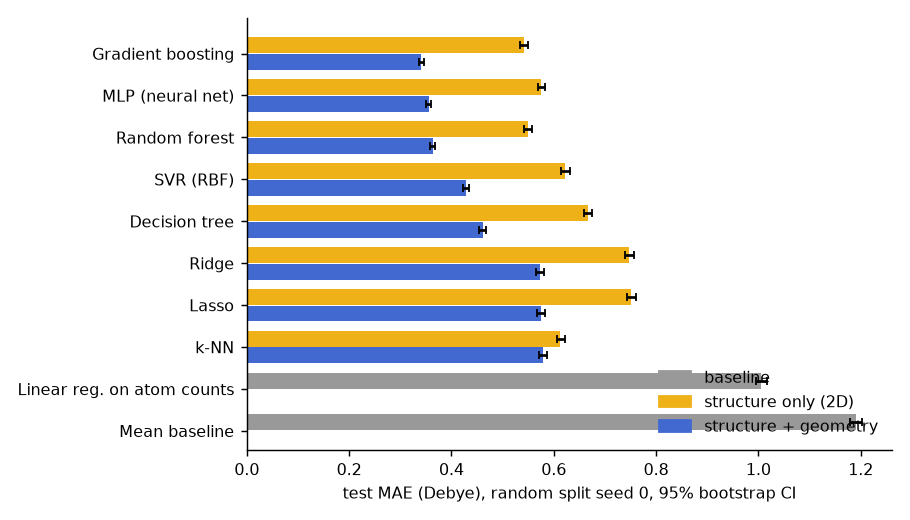

In [3]:
display(Image(FIGURES/'model_comparison.png'))

## Paired bootstrap comparisons on the same test molecules

In [4]:
pd.DataFrame(S['paired_tests']).T

,label,diff,ci_lo,ci_hi,p_boot
full__hgb_vs_2d__hgb,Gradient boosting: full vs structure-only feat...,-0.200297,-0.206,-0.19479,0.0005
full__hgb_vs_full__rf,Full features: gradient boosting vs random forest,-0.021995,-0.025072,-0.019154,0.0005
full__hgb_vs_composition__linreg_comp,Best model vs linear regression on atom counts,-0.664121,-0.674059,-0.654016,0.0005
full__ridge_vs_2d__ridge,Ridge: full vs structure-only features,-0.175129,-0.180914,-0.169384,0.0005
full__hgb_vs_full__svr,Full features: gradient boosting vs SVR,-0.086992,-0.091167,-0.082627,0.0005
full__hgb_vs_full__mlp,Full features: gradient boosting vs MLP,-0.014633,-0.018439,-0.010675,0.0005


## Feature-set ablation (main split)

In [5]:
pd.DataFrame(S['ablation']).pivot(index='featureset_label', columns='model', values='test_mae').round(3)

model,hgb,ridge
featureset_label,,
2D + Coulomb/shape geometry,0.513,0.743
2D + dipole estimates,0.345,0.576
Composition (atom counts),0.950,1.005
Structure + geometry (full),0.341,0.573
Structure only (2D graph),0.542,0.748


In [6]:
pd.DataFrame(S['group_importance'])

,group,label,n_features,base_mae,delta_mae_mean,delta_mae_std
0,comp,Composition,7,0.34197,0.019284,0.000279
1,d2,2D descriptors,208,0.34197,0.833636,0.003215
2,q2,Gasteiger charge stats,4,0.34197,0.025465,0.000395
3,geo,Coulomb eigenvalues + shape,35,0.34197,0.073368,0.000509
4,phys,Dipole estimates (charges x coords),2,0.34197,0.662016,0.002690


## Robustness: scaffold and size-extrapolation splits

In [7]:
pd.DataFrame(S['robustness']).round(3)

,featureset,model,model_label,random_all,random_ring_only,scaffold,size_le8,size_control
0,composition,mean,Mean baseline,1.190,1.176,1.169,1.190,1.197
1,composition,linreg_comp,Linear reg. on atom counts,1.005,0.981,1.008,1.026,1.022
2,2d,ridge,Ridge,0.748,0.721,0.757,0.764,0.758
3,2d,tree,Decision tree,0.667,0.644,0.692,0.726,0.716
4,2d,rf,Random forest,0.549,0.530,0.610,0.645,0.634
5,2d,hgb,Gradient boosting,0.542,0.523,0.605,0.647,0.634
6,full,ridge,Ridge,0.573,0.552,0.570,1.916,0.583
7,full,tree,Decision tree,0.461,0.449,0.510,0.572,0.540
8,full,rf,Random forest,0.363,0.355,0.414,0.467,0.450
9,full,hgb,Gradient boosting,0.341,0.334,0.393,0.450,0.420


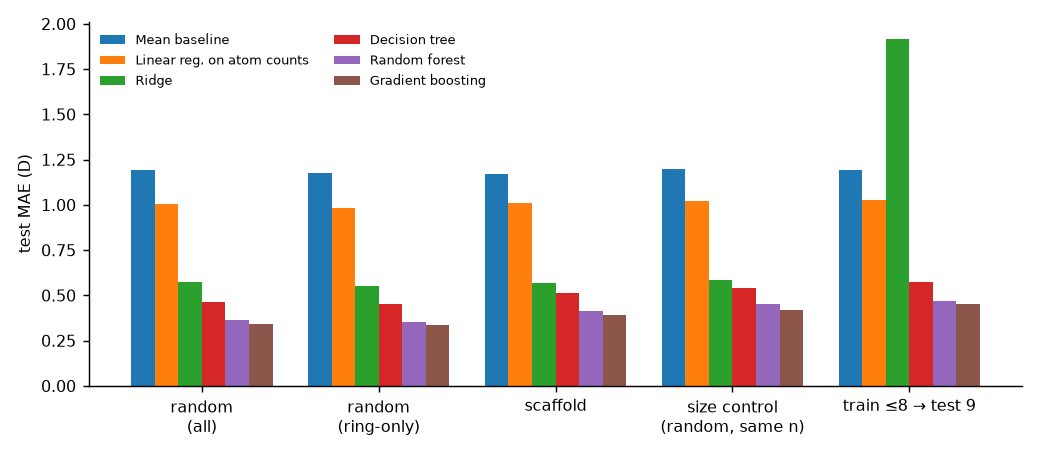

In [8]:
display(Image(FIGURES/'robustness.png'))

## Learning curve

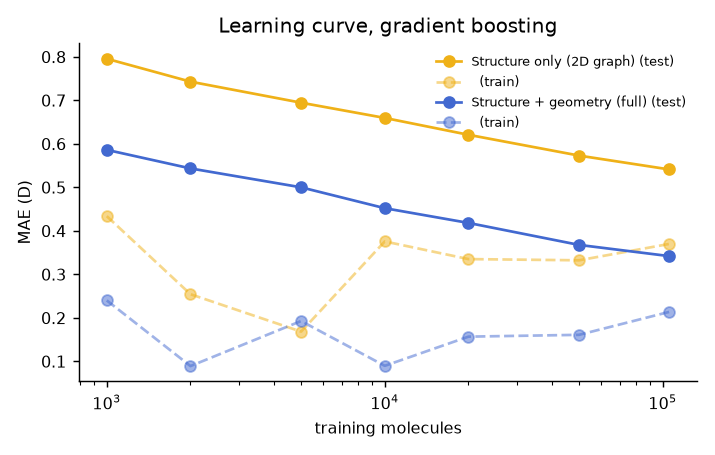

,featureset,n_train,test_mae,train_mae
0,2d,1000,0.796,0.434
1,2d,2000,0.743,0.254
2,2d,5000,0.695,0.168
3,2d,10000,0.660,0.376
4,2d,20000,0.621,0.335
5,2d,50000,0.573,0.332
6,2d,105576,0.541,0.370
7,full,1000,0.586,0.240
8,full,2000,0.544,0.089
9,full,5000,0.500,0.193


In [9]:
display(Image(FIGURES/'learning_curve.png'))
pd.DataFrame(S['learning_curve']).round(3)

## Error analysis (best model: gradient boosting, full features, seed 0)

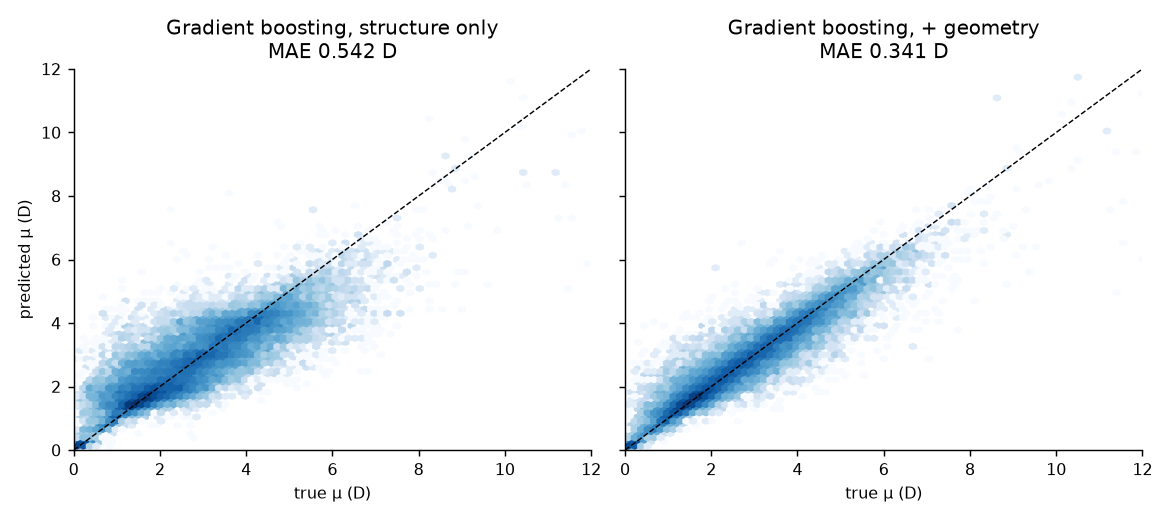

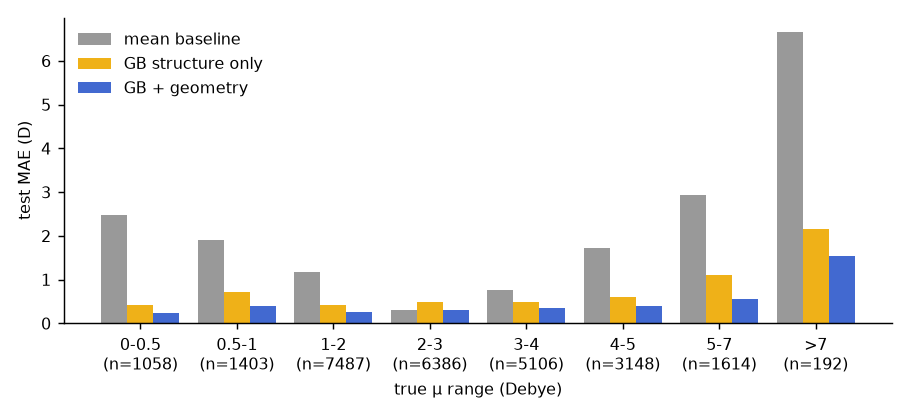

,mu_bin,n,mae,mean_resid,mae_2d,mae_mean_baseline
0,0-0.5,1058,0.229,0.185,0.408,2.477
1,0.5-1,1403,0.386,0.338,0.725,1.915
2,1-2,7487,0.262,0.148,0.417,1.180
3,2-3,6386,0.313,0.042,0.492,0.297
4,3-4,5106,0.353,-0.105,0.490,0.767
5,4-5,3148,0.400,-0.230,0.598,1.728
6,5-7,1614,0.563,-0.459,1.103,2.942
7,>7,192,1.537,-1.118,2.163,6.656


In [10]:
display(Image(FIGURES/'pred_vs_true.png'))
display(Image(FIGURES/'error_by_mu_bin.png'))
pd.DataFrame(S['error_analysis']['by_mu_bin']).round(3)

In [11]:
pd.DataFrame(S['error_analysis']['by_group']).round(3)

,group,n,mae,mae_2d,mean_true,mean_resid
0,Acyclic (no ring),2852,0.405,0.693,3.079,-0.006
1,Aromatic ring,4315,0.596,0.732,3.165,-0.023
2,Nitrile (C#N),3296,0.410,0.735,4.106,-0.005
3,Carbonyl (C=O),9392,0.401,0.666,3.363,-0.006
4,Hydroxyl (OH),8327,0.370,0.597,2.516,0.002
5,Ether (C-O-C),11476,0.306,0.517,2.533,-0.008
6,Primary amine (NH2),3279,0.587,0.762,3.399,-0.035
7,Fluorine,424,0.557,0.738,2.871,0.021
8,Charged / zwitterion,702,0.633,0.840,3.771,0.023
9,Near-zero dipole (<0.5 D),1058,0.229,0.408,0.233,0.185


In [12]:
pd.DataFrame(S['error_analysis']['worst'])

,mol_id,smiles,y_true,pred,2d__hgb,abs_err,comp_nheavy
0,gdb_22974,O=CC(=[N+]=O)C1C[NH2+]C1,14.061,3.722,4.837,10.339,9.0
1,gdb_130454,[NH3+]CCc1cc(=O)o[nH]1,20.982,11.210,8.066,9.772,9.0
2,gdb_129996,NC1Cc2[nH]nnc2N1,14.060,6.872,4.751,7.188,9.0
3,gdb_129994,NC1Cc2cn[nH]c2N1,12.522,5.484,3.025,7.038,9.0
4,gdb_32885,NCCC1=CC(=O)[CH+][OH+]1,11.438,4.988,5.117,6.450,9.0
5,gdb_108410,C[NH2+][C@]12CO[C@H]1[C@H]2C=O,11.943,5.986,5.923,5.958,9.0
6,gdb_130393,[NH3+]Cc1[nH]nnc1CO,11.530,6.551,9.893,4.979,9.0
7,gdb_22195,C[NH2+]C/C(CC#N)=N/O,8.268,13.133,13.447,4.865,9.0
8,gdb_59827,C[NH+](C)C/C=C\C(=O)[O-],13.041,17.857,15.525,4.815,9.0
9,gdb_130385,N/C=[NH+]/Cc1nnn[nH]1,15.861,11.426,13.296,4.435,9.0


In [13]:
{k: v for k, v in S['error_analysis'].items() if not isinstance(v, (list, dict))}

{'resid_true_corr': -0.40264642860866384,
 'frac_within_0_5D': 0.7832840797150867,
 'frac_within_1D': 0.936424945063272,
 'median_abs_err': 0.21032699909210195}